# Olist Delivery Delay: Risk Ranking at Payment Approval

## 1. Business Objective

Customer service can follow up on about **10% of orders**. Rank orders at payment approval so this workload captures as many eventual late deliveries as possible. An order is late when its delivery **calendar date** is after its promised date.

We compare exactly three main models: **Logistic Regression → CatBoost classifier → stacking ensemble**. Select settings by validation **Recall@Top10%**, using average precision to break ties. Precision, lift, workload counts, and capacity curves explain the business trade-off. Accuracy is not a selection metric.

The original validation orders and June 19, 2018 test boundary are retained for comparison. Both halves of validation are now development data; neither is an independent check. The test is evaluated only after all settings are frozen.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.special import logit
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier, CatBoostRegressor
import sklearn, catboost

# Dependencies: pandas, numpy, matplotlib, scipy, scikit-learn >= 1.2, catboost.
# If needed, run: %pip install pandas numpy matplotlib scipy scikit-learn catboost
threadpool_limits(2)
SEED = 5450
T = "order_approved_at"
A = "order_delivered_customer_date"
P = "order_estimated_delivery_date"
VAL = pd.Timestamp("2018-04-12 07:51:25")
TEST = pd.Timestamp("2018-06-19 04:17:02")
ROOT = next(
    p for p in [Path("."), Path("..")] if (p / "data/processed/olist_cleaned.csv").is_file()
)
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print(
    {
        "Python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "CatBoost": catboost.__version__,
    }
)

{'Python': '3.12.3', 'pandas': '2.2.2', 'scikit-learn': '1.5.1', 'CatBoost': '1.2.10'}


## 2. Key EDA Findings

These findings come from `02_EDA.ipynb` and the robustness checks in `03_hypothesis_testing.ipynb`.

| EDA finding | Modeling response | How we check its value |
|---|---|---|
| Geography matters; longer promises protect orders **within** a state | State, city, ZIP prefixes, promise relative to the training state's median | Compare basic and expanded features |
| Freight partly reflects geography; a smaller association remains after controlling for promise length | Log freight, freight per item, region and promise together | Let trees learn nonlinear interactions |
| Multi-seller orders are less often late, although this group is small | Seller/item counts and multi-seller/item indicators | Retain the observed direction; do not assume complexity increases risk |
| Approval time, price, and freight are skewed | Log transforms and training-only scaling for the baseline | Keep unusual valid orders rather than remove rare positives |
| Delay rates change sharply over time | Outcome-availability training, chronological evaluation, and historical regional/seller outcomes | Compare history with and without ongoing updates |
| Individual numeric correlations are weak | Direct nonlinear classification and stacking | Compare all models at the same follow-up budget |

Seller and product IDs are available in the local item table. They describe repeated entities; **product ID is not product category**. Seller coordinates, distance, product categories, weight, and dimensions are absent from the three local raw tables, so we do not invent them.

## 3. Data Preparation and Feature Engineering

Keep the existing order-level cohort for an exact comparison with the previous notebook. Review the raw exclusions and development data below. This cohort contains eventually delivered orders with valid timestamps and shipment after approval; results do not establish performance on cancellations or undelivered orders.

Aggregate items within each order. Use the highest-priced item to identify a representative seller and product, with first occurrence breaking ties. No other order's outcome enters these static features. We exclude shipping deadlines: the cleaning and EDA notebooks disagree about verified availability at approval, and the development data contain implausible deadline values.

In [2]:
df = pd.read_csv(ROOT / "data/processed/olist_cleaned.csv", dtype={"customer_zip_code_prefix": str})
for c in [
    T,
    A,
    P,
    "order_purchase_timestamp",
    "order_delivered_carrier_date",
    "earliest_shipping_limit",
    "latest_shipping_limit",
]:
    df[c] = pd.to_datetime(df[c])
items = pd.read_csv(ROOT / "data/raw/olist_order_items_dataset.csv")
primary = items.loc[
    items.groupby("order_id").price.idxmax(), ["order_id", "seller_id", "product_id"]
]
item_summary = (
    items.groupby("order_id")
    .agg(
        max_price=("price", "max"),
        price_std=("price", "std"),
        max_freight=("freight_value", "max"),
        freight_std=("freight_value", "std"),
        product_count=("product_id", "nunique"),
    )
    .fillna(0)
)
df = (
    df.merge(primary, on="order_id", validate="one_to_one")
    .merge(item_summary, on="order_id", validate="one_to_one")
    .sort_values([T, "order_id"])
    .reset_index(drop=True)
)
df["days"] = (df[A].dt.normalize() - df[T].dt.normalize()).dt.days
# On-time outcomes are known at delivery. A pending order is already late once
# the promised calendar day has ended; its eventual arrival date is unnecessary.
df["known_at"] = pd.concat([df[A], df[P].dt.normalize() + pd.Timedelta(days=1)], axis=1).min(axis=1)
df["zip2"] = df.customer_zip_code_prefix.str.zfill(5).str[:2]
df["zip3"] = df.customer_zip_code_prefix.str.zfill(5).str[:3]
df["seller_state"] = df.seller_id + "_" + df.customer_state
df["city_state"] = df.customer_city + "_" + df.customer_state
assert df.order_id.is_unique and (df.days >= 0).all()
assert (df.known_at >= df[T]).all()
assert np.array_equal((df.days > df.promised_delivery_days).astype(int), df.late_delivery)
assert df[T].iloc[int(0.70 * len(df))] == VAL
assert df[T].iloc[int(0.85 * len(df))] == TEST

development = df.loc[df[T] < TEST].copy()
validation = df.loc[(df[T] >= VAL) & (df[T] < TEST)].copy()
raw_orders = pd.read_csv(ROOT / "data/raw/olist_orders_dataset.csv")
quality = pd.Series(
    {
        "Raw orders": len(raw_orders),
        "Retained comparison cohort": len(df),
        "Development orders": len(development),
        "Development duplicate IDs": development.order_id.duplicated().sum(),
        "Development missing cells": development.isna().sum().sum(),
        "Development late orders": development.late_delivery.sum(),
        "Development deliveries taking >90 days": (development.days > 90).sum(),
        "Development approvals taking >7 days": (development.approval_duration_hours > 168).sum(),
        "Development shipping deadlines >60 days after approval": (
            (development.latest_shipping_limit - development[T]).dt.total_seconds() / 86400 > 60
        ).sum(),
    },
    name="Count",
)
display(quality.to_frame())
display(
    development.groupby("late_delivery")[
        ["promised_delivery_days", "approval_duration_hours", "total_freight", "item_count"]
    ]
    .median()
    .rename(index={0: "On time", 1: "Late"})
    .round(2)
)

,Count
Raw orders,99441
Retained comparison cohort,95104
Development orders,80838
Development duplicate IDs,0
Development missing cells,0
Development late orders,5892
Development deliveries taking >90 days,77
Development approvals taking >7 days,45
Development shipping deadlines >60 days after approval,5


,promised_delivery_days,approval_duration_hours,total_freight,item_count
late_delivery,,,,
On time,24.0,0.33,16.79,1.0
Late,23.0,0.40,18.23,1.0


The cleaned development inputs have no missing values. The baseline nevertheless fits a median imputer on its training rows. Single-item price/freight standard deviations are defined as zero. Sparse or unseen historical groups shrink toward fixed priors (7% late, 15 delivery days); unseen categorical values are handled by the model.

Retain extreme delivery labels. Use logs for skewed inputs and cap **past duration contributions** at 120 days when constructing history, so one unusual record does not dominate a group average. The current order's duration and actual shipment never enter its inputs.

In [3]:
BASIC = [
    "customer_state",
    "promised_delivery_days",
    "item_count",
    "seller_count",
    "purchase_month",
    "purchase_weekday",
    "purchase_hour",
    "approval_duration_hours",
    "total_price",
    "total_freight",
]


def features(d, reference, kind="static"):
    x = d[BASIC].copy()
    if kind == "basic":
        return x
    for c in [
        "total_price",
        "total_freight",
        "approval_duration_hours",
        "max_price",
        "price_std",
        "max_freight",
        "freight_std",
    ]:
        x["log_" + c] = np.log1p(d[c].clip(lower=0))
    x = x.drop(columns=["total_price", "total_freight", "approval_duration_hours"])
    for c in ["seller_id", "product_id", "city_state", "zip2", "zip3", "product_count"]:
        x[c] = d[c]
    for c in ["promised_delivery_days", "total_freight"]:
        med = reference.groupby("customer_state")[c].median()
        x["relative_" + c] = d[c] - d.customer_state.map(med).fillna(reference[c].median())
    x["freight_per_item"] = d.total_freight / d.item_count
    x["price_per_item"] = d.total_price / d.item_count
    x["freight_price_ratio"] = d.total_freight / (d.total_price + 1)
    x["multi_seller"] = (d.seller_count > 1).astype(int)
    x["multi_item"] = (d.item_count > 1).astype(int)
    x["approval_fraction"] = d.approval_duration_hours / (
        24 * d.promised_delivery_days.clip(lower=1)
    )
    x["approval_weekday"] = d[T].dt.dayofweek
    x["promised_weekday"] = d[P].dt.dayofweek
    x["weekend"] = (d.order_purchase_timestamp.dt.dayofweek >= 5).astype(int)
    x["calendar_day"] = (d[T] - pd.Timestamp("2016-01-01")).dt.total_seconds() / 86400
    for c, period in [("purchase_month", 12), ("purchase_weekday", 7), ("purchase_hour", 24)]:
        x[c + "_sin"] = np.sin(2 * np.pi * d[c] / period)
        x[c + "_cos"] = np.cos(2 * np.pi * d[c] / period)
    return x


# Months and a long-term trend were unstable under the chronological split.
DROP_TIME = ["calendar_day", "purchase_month", "purchase_month_sin", "purchase_month_cos"]


def engineered(part, reference, history=None):
    x = features(part, reference).drop(columns=DROP_TIME)
    return x if history is None else x.join(history)

**Historical features use event time, not just order time.** For state, seller, ZIP3, and seller–state, compute smoothed previous delay rates (all history and last 90 days), observed delivery times, counts, and the current promise minus historical delivery time.

An event contributes only if it occurred **strictly before** the order's approval. Delay-rate events use `known_at`; duration events require completed delivery. Historical features update sequentially during validation and test when earlier orders' outcomes become known. Model parameters stay fixed throughout each evaluation period. Thus an earlier test order can inform a later test order only after its outcome is observable; it cannot inform its own prediction or model selection. This assumes the operational system maintains an outcome history. We also report a frozen-history sensitivity check.

In [4]:
def historical_features(source, query, cutoff):
    """Outcome events strictly before min(order approval, model cutoff)."""
    query = query.copy()
    qtime = np.minimum(query[T].to_numpy(dtype="datetime64[ns]"), np.datetime64(cutoff, "ns"))
    result = pd.DataFrame(index=query.index)
    groups = ["customer_state", "seller_id", "zip3", "seller_state"]
    for group in groups:
        # Delayed label becomes known when delivery occurs or the deadline expires.
        for event, value, prior, windows in [
            ("known_at", "late_delivery", 0.07, [None, 90]),
            (A, "days", 15.0, [None]),
        ]:
            src = source.loc[source[event] < cutoff, [group, event, value]].copy()
            src = src.sort_values(event)
            for window in windows:
                counts = np.zeros(len(query))
                sums = np.zeros(len(query))
                qgroups = query.groupby(group, sort=False).indices
                for key, g in src.groupby(group, sort=False):
                    ii = qgroups.get(key)
                    if ii is None:
                        continue
                    ts = g[event].to_numpy(dtype="datetime64[ns]")
                    vals = g[value].to_numpy(float)
                    if value == "days":
                        vals = np.clip(vals, 0, 120)
                    cs = np.r_[0.0, np.cumsum(vals)]
                    hi = np.searchsorted(ts, qtime[ii], side="left")
                    used = hi > 0
                    assert (ts[hi[used] - 1] < qtime[ii][used]).all()
                    lo = (
                        np.zeros(len(ii), int)
                        if window is None
                        else np.searchsorted(
                            ts, qtime[ii] - np.timedelta64(window, "D"), side="left"
                        )
                    )
                    counts[ii] = hi - lo
                    sums[ii] = cs[hi] - cs[lo]
                alpha = 30 if group in ["customer_state", "zip3"] else 15
                tag = f'{group}_{value}_{window or "all"}'
                result[tag] = (sums + alpha * prior) / (counts + alpha)
                result[tag + "_count"] = np.log1p(counts)
                if value == "days":
                    result[group + "_arrival_buffer"] = (
                        query.promised_delivery_days.to_numpy() - result[tag].to_numpy()
                    )
    return result

## 4. Data Splitting and Training Strategy

Retain the original approximate **70% / 15% / 15% approval-time boundaries**. Training size is lower than the nominal 70% because unresolved labels are excluded. A fixed 30–45 day gap is not necessary for binary classification: keep every earlier approval whose label is already known. This recovers pending-but-already-late positives without using their future delivery dates.

We compare alternative gaps, delivered-only training, and smaller training windows. More recent negatives can resolve sooner than positives, so outcome-availability selection is still imperfect. We do not call this a complete correction for censoring.

Use the entire validation period for development, and report both halves to reveal time instability. The previously used later half is not a new holdout. EDA examined the full dataset earlier; the final test is untouched by this redesign's model selection, but is not a fully blind external validation.

,Part,Orders,Late,Late rate,First approval,Last approval
0,Available training labels,64019,4753,0.0742,2016-09-15 12:16:38,2018-04-10 12:10:54
1,Validation: early,7133,317,0.0444,2018-04-12 07:51:25,2018-05-12 20:10:23
2,Validation: later,7133,318,0.0446,2018-05-12 20:10:25,2018-06-19 04:16:58


Reserved test orders: 14266 | start: 2018-06-19 04:17:02


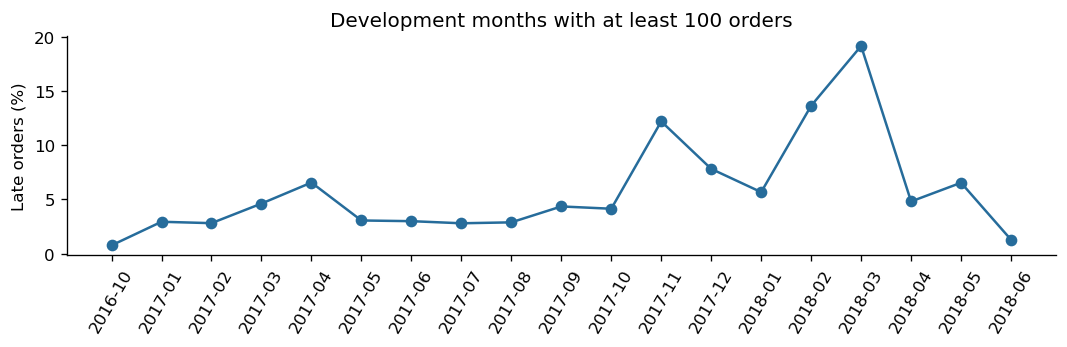

Sparse months are omitted only from this plot. June ends at the test boundary.


,Feature,Training categories,Unseen in validation (%)
0,seller_id,2087,12.19
1,product_id,21577,42.36
2,city_state,3819,1.65
3,zip3,846,0.02


In [5]:
def training(d, cutoff=VAL, gap=0, window=None, mode="known"):
    m = (d[T] < cutoff - pd.Timedelta(days=gap)) & (
        d["known_at" if mode == "known" else A] < cutoff
    )
    if window:
        m &= d[T] >= cutoff - pd.Timedelta(days=window)
    return d[m].copy()


train = training(df)
history = historical_features(development, pd.concat([train, validation]), TEST)
assert train.known_at.max() < VAL
assert train[T].max() < VAL
assert not set(train.order_id) & set(validation.order_id)
assert not history.isna().any().any()

parts = []
for label, part in [
    ("Available training labels", train),
    ("Validation: early", validation.iloc[:7133]),
    ("Validation: later", validation.iloc[7133:]),
]:
    parts.append(
        {
            "Part": label,
            "Orders": len(part),
            "Late": int(part.late_delivery.sum()),
            "Late rate": part.late_delivery.mean(),
            "First approval": part[T].min(),
            "Last approval": part[T].max(),
        }
    )
display(pd.DataFrame(parts).round(4))
print("Reserved test orders:", (df[T] >= TEST).sum(), "| start:", TEST)
monthly = development.groupby(development[T].dt.to_period("M")).late_delivery.agg(["size", "mean"])
monthly_plot = monthly.loc[monthly["size"] >= 100]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(monthly_plot.index.astype(str), monthly_plot["mean"] * 100, marker="o", color="#266c9b")
ax.set(ylabel="Late orders (%)", title="Development months with at least 100 orders")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()
print("Sparse months are omitted only from this plot. June ends at the test boundary.")

novelty = [
    {
        "Feature": c,
        "Training categories": train[c].nunique(),
        "Unseen in validation (%)": 100 * (~validation[c].isin(train[c])).mean(),
    }
    for c in ["seller_id", "product_id", "city_state", "zip3"]
]
display(pd.DataFrame(novelty).round(2))

In [6]:
def top_indices(scores, capacity=0.10):
    scores = np.asarray(scores, dtype=float)
    assert np.isfinite(scores).all()
    k = int(np.ceil(capacity * len(scores)))
    ties = np.random.default_rng(SEED).random(len(scores))
    return np.lexsort((ties, -scores))[:k]


def evaluate(y, scores, capacity=0.10):
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    assert len(y) == len(scores) and y.sum() > 0
    chosen = top_indices(scores, capacity)
    found = int(y[chosen].sum())
    recall, precision = found / y.sum(), found / len(chosen)
    return {
        "Selected": len(chosen),
        "Found": found,
        "False alerts": len(chosen) - found,
        "Missed": int(y.sum()) - found,
        "Recall": recall,
        "Precision": precision,
        "Lift": precision / y.mean(),
        "AP": average_precision_score(y, scores),
        "ROC-AUC": roc_auc_score(y, scores),
    }


def validation_result(scores):
    out = evaluate(validation.late_delivery, scores)
    for name, section in [("Early recall", slice(None, 7133)), ("Later recall", slice(7133, None))]:
        out[name] = evaluate(validation.late_delivery.iloc[section], scores[section])["Recall"]
    return out


def show_results(table, columns=None):
    if columns is not None:
        table = table[columns]
    formats = {
        c: "{:.1%}"
        for c in table.columns
        if c in ["Recall", "Precision", "Early recall", "Later recall", "Late rate"]
    }
    formats.update({c: "{:.3f}" for c in ["AP", "ROC-AUC"] if c in table})
    formats.update(
        {
            c: "{:,.0f}"
            for c in [
                "Selected",
                "Found",
                "False alerts",
                "Missed",
                "Orders",
                "Late training orders",
                "Training rows",
            ]
            if c in table
        }
    )
    if "Lift" in table:
        formats["Lift"] = "{:.2f}x"
    display(table.style.format(formats))

## 5. Model 1: Logistic Regression Baseline

Use the original basic numeric fields and state one-hot encoding. Log-transform price, freight, and approval duration, then standardize numeric inputs. Tune regularization and class weighting on validation; the baseline receives a fair optimization budget.

In [7]:
def logistic(train, val, C=1, balanced=True, log=False):
    x = features(train, train, "basic")
    z = features(val, train, "basic")
    nums = x.select_dtypes("number").columns.tolist()
    if log:
        for c in ["total_price", "total_freight", "approval_duration_hours"]:
            x[c] = np.log1p(x[c])
            z[c] = np.log1p(z[c])
    prep = ColumnTransformer(
        [
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums),
            ("cat", OneHotEncoder(handle_unknown="ignore"), ["customer_state"]),
        ]
    )
    m = make_pipeline(
        prep,
        LogisticRegression(
            C=C, class_weight="balanced" if balanced else None, max_iter=2000, random_state=SEED
        ),
    )
    m.fit(x, train.late_delivery)
    return m, m.predict_proba(z)[:, 1]


baseline_trials, baseline_models, baseline_scores = [], {}, {}
for C in [0.01, 0.1, 1, 10]:
    for balanced in [False, True]:
        name = f"C={C}, balanced={balanced}"
        model, scores = logistic(train, validation, C=C, balanced=balanced, log=True)
        baseline_models[name] = model
        baseline_scores[name] = scores
        baseline_trials.append(
            {"Setting": name, "C": C, "Balanced": balanced, **validation_result(scores)}
        )
baseline_table = pd.DataFrame(baseline_trials).sort_values(["Recall", "AP"], ascending=False)
selected_lr = baseline_table.iloc[0]
lr_C, lr_balanced = float(selected_lr.C), bool(selected_lr.Balanced)
lr_model = baseline_models[selected_lr.Setting]
lr_val = baseline_scores[selected_lr.Setting]
show_results(baseline_table.set_index("Setting"), ["Recall", "Early recall", "Later recall", "AP"])

,Recall,Early recall,Later recall,AP
Setting,,,,
"C=10, balanced=False",33.9%,32.8%,34.0%,0.121
"C=1, balanced=False",33.4%,32.8%,33.6%,0.121
"C=1, balanced=True",33.2%,30.9%,34.0%,0.118
"C=0.1, balanced=True",33.2%,30.6%,34.3%,0.117
"C=10, balanced=True",33.1%,30.9%,34.0%,0.118
"C=0.1, balanced=False",32.9%,32.2%,34.9%,0.120
"C=0.01, balanced=True",31.5%,29.7%,33.6%,0.114
"C=0.01, balanced=False",30.6%,28.1%,33.3%,0.111


In [8]:
# Hold baseline settings constant to isolate training-label availability.
policy_rows = []
for name, gap, mode in [
    ("Old 30d / delivered", 30, "delivered"),
    ("Old 45d / delivered", 45, "delivered"),
    ("No gap / delivered", 0, "delivered"),
    ("No gap / known labels", 0, "known"),
]:
    sample = training(df, gap=gap, mode=mode)
    _, p = logistic(sample, validation, C=1, balanced=True, log=False)
    policy_rows.append(
        {
            "Training rule": name,
            "Orders": len(sample),
            "Late training orders": int(sample.late_delivery.sum()),
            "Recall": evaluate(validation.late_delivery, p)["Recall"],
        }
    )
show_results(pd.DataFrame(policy_rows).set_index("Training rule"))

,Orders,Late training orders,Recall
Training rule,,,
Old 30d / delivered,"59,522","4,095",32.8%
Old 45d / delivered,"56,082","3,439",30.7%
No gap / delivered,"63,499","4,233",33.4%
No gap / known labels,"64,019","4,753",33.2%


The broader development search also tested 90-, 180-, and 365-day training windows using the same expanded, calendar-aware CatBoost configuration (500 trees, depth 6, late weight 3). Validation recall was **28.2%, 29.3%, and 32.4%**, respectively. Restricting training to the last 90 or 180 days concentrated the February–March high-delay regime and lost older examples. We retain the full available history.

The following diagnostic compares **the same static classifier** under shuffled stratified folds and chronological cutoffs. No outcome-history features are used in the shuffled experiment. Random folds mix time regimes and let the model learn from dates later than some evaluated orders. They answer an interpolation question and are not the deployment estimate. AP also changes with class prevalence.

In [9]:
def cat_fit(
    x,
    y,
    z,
    weight=1,
    depth=6,
    iters=500,
    l2=10,
    lr=0.05,
    objective="class",
    days=None,
    promise=None,
):
    cats = x.select_dtypes("object").columns.tolist()
    klass = CatBoostClassifier if objective == "class" else CatBoostRegressor
    loss = {"class": "Logloss", "time": "RMSE", "q80": "Quantile:alpha=0.8", "delay": "RMSE"}[
        objective
    ]
    m = klass(
        iterations=iters,
        depth=depth,
        learning_rate=lr,
        l2_leaf_reg=l2,
        cat_features=cats,
        has_time=True,
        thread_count=4,
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False,
        loss_function=loss,
    )
    target = y if objective == "class" else (days - promise if objective == "delay" else days)
    m.fit(x, target, sample_weight=np.where(y == 1, weight, 1))
    p = m.predict_proba(z)[:, 1] if objective == "class" else m.predict(z)
    return m, p


split_rows = []
random_pool = training(df, TEST)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
for fold, (a, b) in enumerate(cv.split(random_pool, random_pool.late_delivery), start=1):
    a, b = random_pool.iloc[a].sort_values(T), random_pool.iloc[b].sort_values(T)
    _, p = cat_fit(features(a, a), a.late_delivery, features(b, a), depth=4, iters=200)
    split_rows.append(
        {
            "Split": f"Random stratified fold {fold}",
            "Train": len(a),
            "Evaluation": len(b),
            "Late rate": b.late_delivery.mean(),
            **{k: evaluate(b.late_delivery, p)[k] for k in ["Recall", "AP"]},
        }
    )
for fraction in [0.60, 0.70]:
    sample = training(df, df[T].iloc[int(fraction * len(df))])
    _, p = cat_fit(
        features(sample, sample),
        sample.late_delivery,
        features(validation, sample),
        depth=4,
        iters=200,
    )
    split_rows.append(
        {
            "Split": f"Chronological: first {fraction:.0%} approvals",
            "Train": len(sample),
            "Evaluation": len(validation),
            "Late rate": validation.late_delivery.mean(),
            **{k: evaluate(validation.late_delivery, p)[k] for k in ["Recall", "AP"]},
        }
    )
show_results(pd.DataFrame(split_rows).set_index("Split"))

,Train,Evaluation,Late rate,Recall,AP
Split,,,,,
Random stratified fold 1,52576,26288,7.4%,40.0%,0.288
Random stratified fold 2,52576,26288,7.4%,38.8%,0.282
Random stratified fold 3,52576,26288,7.4%,40.9%,0.303
Chronological: first 60% approvals,53686,14266,4.5%,26.0%,0.093
Chronological: first 70% approvals,64019,14266,4.5%,30.7%,0.118


## 6. Model 2: Advanced Machine Learning Model

Use **direct binary classification**, with expanded static inputs and strictly prior outcome histories. CatBoost models repeated seller/product identities and nonlinear interactions without treating IDs as ordered numbers.

The development search compared CatBoost and XGBoost; static, historical, and recent workload features; class weights 1/3/10; depths 3–8; calendar removal; training windows; and categorical encoding settings. Extra workload features with XGBoost reached 35.6% validation recall. The smaller CatBoost history feature set performed better in the shortlist below. More complexity did not consistently help.

The shortlist is rerun here. All settings use the full outcome-available training set. We remove raw month and the long-term calendar trend from the expanded inputs because their effects changed across periods. Weekday, hour, and weekend information remain.

In [10]:
x_train = engineered(train, train, history)
x_val = engineered(validation, train, history)
forbidden = {
    A,
    "order_delivered_carrier_date",
    "late_delivery",
    "days",
    "known_at",
    "order_id",
    "customer_id",
    "earliest_shipping_limit",
    "latest_shipping_limit",
}
assert not set(x_train) & forbidden
assert not x_train.isna().any().any()

settings = [
    (3, 500, 10, 1),
    (4, 500, 10, 1),
    (4, 1000, 20, 1),
    (5, 500, 20, 1),
    (4, 500, 30, 1),
    (4, 500, 10, 3),
]
advanced_rows, advanced_models, advanced_scores = [], {}, {}
for depth, iterations, regularization, weight in settings:
    name = f"depth={depth}, trees={iterations}, L2={regularization}, weight={weight}"
    model, p = cat_fit(
        x_train,
        train.late_delivery,
        x_val,
        depth=depth,
        iters=iterations,
        l2=regularization,
        weight=weight,
    )
    advanced_models[name], advanced_scores[name] = model, p
    advanced_rows.append(
        {
            "Setting": name,
            "Depth": depth,
            "Trees": iterations,
            "L2": regularization,
            "Weight": weight,
            **validation_result(p),
        }
    )
advanced_table = pd.DataFrame(advanced_rows).sort_values(["Recall", "AP"], ascending=False)
chosen = advanced_table.iloc[0]
advanced_model = advanced_models[chosen.Setting]
advanced_val = advanced_scores[chosen.Setting]
advanced_params = dict(
    depth=int(chosen.Depth),
    iters=int(chosen.Trees),
    l2=float(chosen.L2),
    weight=float(chosen.Weight),
)
show_results(advanced_table.set_index("Setting"), ["Recall", "Early recall", "Later recall", "AP"])

,Recall,Early recall,Later recall,AP
Setting,,,,
"depth=4, trees=500, L2=30, weight=1",36.2%,37.2%,35.5%,0.139
"depth=3, trees=500, L2=10, weight=1",35.7%,36.3%,36.2%,0.138
"depth=4, trees=500, L2=10, weight=1",35.3%,35.6%,37.4%,0.136
"depth=4, trees=1000, L2=20, weight=1",34.8%,35.0%,35.8%,0.140
"depth=5, trees=500, L2=20, weight=1",34.2%,31.9%,36.2%,0.126
"depth=4, trees=500, L2=10, weight=3",34.0%,32.5%,36.8%,0.132


**Feature and objective checks.** Hold the selected CatBoost settings fixed to compare basic inputs, expanded static inputs, and historical inputs. Frozen histories stop at the validation start; sequential histories update only from already-observed events. Timing models can use only deliveries completed before training, because their numerical targets require the arrival date.

In [11]:
ablation = []
for label, kind in [("Basic features", "basic"), ("Expanded static features", "expanded")]:
    a = features(train, train, "basic") if kind == "basic" else engineered(train, train)
    b = features(validation, train, "basic") if kind == "basic" else engineered(validation, train)
    _, p = cat_fit(a, train.late_delivery, b, **advanced_params)
    ablation.append({"Experiment": label, **validation_result(p)})
frozen_val_history = historical_features(development, validation, VAL)
frozen_val = advanced_model.predict_proba(engineered(validation, train, frozen_val_history))[:, 1]
ablation.extend(
    [
        {"Experiment": "Expanded + frozen history", **validation_result(frozen_val)},
        {"Experiment": "Expanded + sequential history", **validation_result(advanced_val)},
    ]
)
completed = training(df, mode="delivered")
for objective in ["time", "q80"]:
    a, b = engineered(completed, completed, history), engineered(validation, completed, history)
    _, arrival = cat_fit(
        a,
        completed.late_delivery,
        b,
        objective=objective,
        days=completed.days,
        promise=completed.promised_delivery_days,
        **advanced_params
    )
    p = arrival - validation.promised_delivery_days.to_numpy()
    ablation.append(
        {
            "Experiment": "Arrival RMSE" if objective == "time" else "Arrival quantile 80%",
            **validation_result(p),
        }
    )
show_results(
    pd.DataFrame(ablation).set_index("Experiment"), ["Recall", "Early recall", "Later recall", "AP"]
)

,Recall,Early recall,Later recall,AP
Experiment,,,,
Basic features,28.5%,25.9%,29.9%,0.099
Expanded static features,30.7%,28.4%,32.7%,0.115
Expanded + frozen history,32.9%,35.3%,37.4%,0.130
Expanded + sequential history,36.2%,37.2%,35.5%,0.139
Arrival RMSE,32.1%,26.2%,37.4%,0.126
Arrival quantile 80%,34.2%,30.3%,38.4%,0.132


**Imbalance checks.** Compare duplication and negative undersampling using the same exploratory depth-4 CatBoost configuration (500 trees, L2=10). Resampling is confined to training; validation prevalence and the 10% workload are unchanged. Duplicating positives can interact poorly with ordered categorical encoding, because repeated copies share both IDs and labels. These results concern the tested methods, not every possible resampling method.

In [12]:
rng = np.random.default_rng(SEED)
y_train = train.late_delivery.to_numpy()
pos, neg = np.flatnonzero(y_train == 1), np.flatnonzero(y_train == 0)
sampling_rows = []
for name, indices in [
    ("Original training", np.arange(len(train))),
    ("Positive duplication x3", np.sort(np.r_[np.arange(len(train)), np.tile(pos, 2)])),
    (
        "Negative undersampling 4:1",
        np.sort(np.r_[pos, rng.choice(neg, 4 * len(pos), replace=False)]),
    ),
]:
    _, p = cat_fit(x_train.iloc[indices], train.late_delivery.iloc[indices], x_val, depth=4)
    sampling_rows.append(
        {
            "Strategy": name,
            "Training rows": len(indices),
            "Recall": evaluate(validation.late_delivery, p)["Recall"],
        }
    )
show_results(pd.DataFrame(sampling_rows).set_index("Strategy"))

,Training rows,Recall
Strategy,,
Original training,"64,019",35.3%
Positive duplication x3,"73,525",12.4%
Negative undersampling 4:1,"23,765",35.3%


## 7. Model 3: Stacking Ensemble

Generate six chronological out-of-fold blocks from October 2017 through March 2018. Each base model is trained on approvals and labels available **before its block starts**. Only OOF labels known before the validation start enter meta-training. No in-sample base predictions train the meta-learner.

Compare Logistic meta-learners on probabilities and log-odds, a nonlinear meta-learner, a shorter meta-training window, and fixed blends. Choose the trained stack using the same validation recall criterion. Blends are supplementary comparisons. A small gain does not establish a reliable improvement.

In [13]:
fold_edges = list(
    pd.to_datetime(
        ["2017-10-01", "2017-11-01", "2017-12-01", "2018-01-01", "2018-02-01", "2018-03-01"]
    )
) + [VAL]
oof_parts, fold_audit = [], []
for start, end in zip(fold_edges[:-1], fold_edges[1:]):
    a = training(df, start)
    b = train.loc[(train[T] >= start) & (train[T] < end)]
    assert a.known_at.max() < start and a[T].max() < b[T].min()
    _, p_lr = logistic(a, b, C=lr_C, balanced=lr_balanced, log=True)
    _, p_adv = cat_fit(
        engineered(a, a, history), a.late_delivery, engineered(b, a, history), **advanced_params
    )
    oof_parts.append(
        pd.DataFrame(
            {
                "lr": p_lr,
                "advanced": p_adv,
                "y": b.late_delivery,
                "approval": b[T],
                "known_at": b.known_at,
            },
            index=b.index,
        )
    )
    fold_audit.append(
        {
            "Block start": start,
            "Training rows": len(a),
            "OOF rows": len(b),
            "Latest training label": a.known_at.max(),
        }
    )
oof = pd.concat(oof_parts).sort_index()
assert oof.index.is_unique and oof.known_at.max() < VAL
assert not set(oof.index) & set(validation.index)
display(pd.DataFrame(fold_audit))
print(f"OOF meta-training: {len(oof):,} orders; {oof.y.sum():,} delays.")

,Block start,Training rows,OOF rows,Latest training label
0,2017-10-01,24792,4441,2017-09-30 20:09:53
1,2017-11-01,29268,7149,2017-10-31 23:59:10
2,2017-12-01,33956,5669,2017-11-30 23:59:03
3,2018-01-01,41432,6990,2017-12-31 15:19:16
4,2018-02-01,47770,6499,2018-01-31 23:58:36
5,2018-03-01,53646,6992,2018-02-28 23:53:56


OOF meta-training: 37,740 orders; 3,806 delays.


In [14]:
def meta_inputs(pair, form):
    pair = np.clip(np.asarray(pair), 1e-6, 1 - 1e-6)
    return logit(pair) if form == "logit" else pair


val_pair = np.c_[lr_val, advanced_val]
stack_rows, stack_models, stack_scores = [], {}, {}
for window in ["all", "recent"]:
    sample = oof if window == "all" else oof.loc[oof.approval >= "2018-01-01"]
    for form in ["raw", "logit"]:
        for C in [0.1, 1, 10]:
            name = f"Logistic / {window} / {form} / C={C}"
            meta = make_pipeline(
                StandardScaler(), LogisticRegression(C=C, max_iter=1000, random_state=SEED)
            )
            meta.fit(meta_inputs(sample[["lr", "advanced"]], form), sample.y)
            p = meta.predict_proba(meta_inputs(val_pair, form))[:, 1]
            stack_models[name] = (meta, window, form)
            stack_scores[name] = p
            stack_rows.append({"Setting": name, "Trained stack": True, **validation_result(p)})
    for leaves in [4, 8]:
        name = f"Nonlinear / {window} / leaves={leaves}"
        meta = HistGradientBoostingClassifier(
            max_iter=100,
            max_leaf_nodes=leaves,
            min_samples_leaf=150,
            l2_regularization=10,
            learning_rate=0.05,
            random_state=SEED,
        )
        meta.fit(sample[["lr", "advanced"]].to_numpy(), sample.y)
        p = meta.predict_proba(val_pair)[:, 1]
        stack_models[name] = (meta, window, "raw")
        stack_scores[name] = p
        stack_rows.append({"Setting": name, "Trained stack": True, **validation_result(p)})
for weight in [0.25, 0.5, 0.75]:
    p = weight * lr_val + (1 - weight) * advanced_val
    stack_rows.append(
        {"Setting": f"Blend: LR weight={weight}", "Trained stack": False, **validation_result(p)}
    )
stack_table = pd.DataFrame(stack_rows).sort_values(["Recall", "AP"], ascending=False)
selected_stack = stack_table.loc[stack_table["Trained stack"]].iloc[0].Setting
meta_model, meta_window, meta_form = stack_models[selected_stack]
stack_val = stack_scores[selected_stack]
# Show each strategy's strongest setting, avoiding a table of near-identical C values.
compact_stack = stack_table.assign(
    Family=stack_table.Setting.str.replace(r" / C=.*", "", regex=True)
)
show_results(
    compact_stack.drop_duplicates("Family").set_index("Setting"),
    ["Recall", "Early recall", "Later recall", "AP"],
)
print("Selected trained stack:", selected_stack)

lr_hits = set(validation.index[top_indices(lr_val)]) & set(
    validation.index[validation.late_delivery == 1]
)
adv_hits = set(validation.index[top_indices(advanced_val)]) & set(
    validation.index[validation.late_delivery == 1]
)
display(
    pd.Series(
        {
            "Found by both": len(lr_hits & adv_hits),
            "Found only by Logistic": len(lr_hits - adv_hits),
            "Found only by CatBoost": len(adv_hits - lr_hits),
        },
        name="Delayed orders",
    ).to_frame()
)

,Recall,Early recall,Later recall,AP
Setting,,,,
Blend: LR weight=0.25,36.7%,38.2%,37.4%,0.145
Logistic / all / logit / C=0.1,36.7%,37.2%,34.9%,0.144
Blend: LR weight=0.5,36.2%,37.2%,35.5%,0.146
Logistic / recent / logit / C=0.1,35.7%,36.9%,33.3%,0.139
Logistic / all / raw / C=0.1,35.7%,36.0%,33.6%,0.133
Blend: LR weight=0.75,35.6%,36.9%,34.0%,0.137
Logistic / recent / raw / C=10,35.4%,35.3%,34.0%,0.131
Nonlinear / all / leaves=4,32.8%,36.3%,31.1%,0.121
Nonlinear / recent / leaves=4,29.9%,31.2%,28.9%,0.115


Selected trained stack: Logistic / all / logit / C=0.1


,Delayed orders
Found by both,151
Found only by Logistic,64
Found only by CatBoost,79


## 8. Model Evaluation and Comparison

First compare development results on the same 14,266 validation orders used previously. Ranking each half separately uses its own 10% budget, so the two half-period hit counts need not sum to the globally ranked validation count. The historical inputs and training-label policy have changed; this is a pipeline comparison, not an isolated algorithm comparison.

The old figures below are the actual saved outputs preserved in `backups/04_modeling_before_redesign_2026-11-24.ipynb`. The old 40.9% result applies only to the later half, not to the full validation period.

In [15]:
MODEL_NAMES = ["Logistic Regression", "CatBoost classifier", "Stacking ensemble"]
validation_scores = dict(zip(MODEL_NAMES, [lr_val, advanced_val, stack_val]))
validation_table = pd.DataFrame(
    {name: validation_result(p) for name, p in validation_scores.items()}
).T
show_results(
    validation_table, ["Found", "Recall", "Early recall", "Later recall", "Precision", "AP"]
)
previous = pd.DataFrame(
    [
        {"Pipeline": "Previous Logistic", "Recall": 208 / 635, "Later recall": 109 / 318},
        {"Pipeline": "Previous CatBoost arrival", "Recall": 207 / 635, "Later recall": 130 / 318},
        *[
            {"Pipeline": name, "Recall": row.Recall, "Later recall": row["Later recall"]}
            for name, row in validation_table.iterrows()
        ],
    ]
).set_index("Pipeline")
show_results(previous)

,Found,Recall,Early recall,Later recall,Precision,AP
Logistic Regression,215,33.9%,32.8%,34.0%,15.1%,0.121
CatBoost classifier,230,36.2%,37.2%,35.5%,16.1%,0.139
Stacking ensemble,233,36.7%,37.2%,34.9%,16.3%,0.144


,Recall,Later recall
Pipeline,,
Previous Logistic,32.8%,34.3%
Previous CatBoost arrival,32.6%,40.9%
Logistic Regression,33.9%,34.0%
CatBoost classifier,36.2%,35.5%
Stacking ensemble,36.7%,34.9%


**Freeze and refit.** Freeze the features, algorithm settings, history-update rule, meta-learning strategy, and 10% capacity before scoring the test. Refit the two base models using all pre-test approvals with labels known before June 19. For the final meta-learner, add the original validation base predictions to the earlier OOF predictions, retaining only labels known before June 19. These validation predictions were made by models trained before validation, not by the final refitted models.

Test predictions are generated with fixed fitted models. Sequential history uses only past observable outcomes, including earlier test orders when their labels become known. No test outcome selects parameters, weights, features, or models. The frozen-history comparison below makes the dependence on ongoing history updates explicit.

In [16]:
frozen_configuration = {
    "Logistic C": lr_C,
    "Logistic balanced": lr_balanced,
    "CatBoost": advanced_params,
    "Stack": selected_stack,
    "Capacity": 0.10,
    "History": "strictly prior events; sequential updates",
}
print("Frozen configuration:", frozen_configuration)
final_train = training(df, TEST)
test = df.loc[df[T] >= TEST].copy()
assert final_train.known_at.max() < TEST
assert not set(final_train.order_id) & set(test.order_id)
assert len(test) == 14266

history_end = test[T].max() + pd.Timedelta(nanoseconds=1)
final_history = historical_features(df, pd.concat([final_train, test]), history_end)
final_lr, test_lr = logistic(final_train, test, C=lr_C, balanced=lr_balanced, log=True)
final_advanced, test_adv = cat_fit(
    engineered(final_train, final_train, final_history),
    final_train.late_delivery,
    engineered(test, final_train, final_history),
    **advanced_params,
)
validation_oof = pd.DataFrame(
    {
        "lr": lr_val,
        "advanced": advanced_val,
        "y": validation.late_delivery,
        "approval": validation[T],
        "known_at": validation.known_at,
    },
    index=validation.index,
)
final_meta_data = pd.concat([oof, validation_oof.loc[validation_oof.known_at < TEST]])
assert final_meta_data.index.is_unique
assert final_meta_data.known_at.max() < TEST
if meta_window == "recent":
    # Preserve the selected recent-window rule relative to the new refit date.
    final_meta_data = final_meta_data.loc[
        final_meta_data.approval >= TEST - (VAL - pd.Timestamp("2018-01-01"))
    ]
final_meta = clone(meta_model)
final_meta.fit(meta_inputs(final_meta_data[["lr", "advanced"]], meta_form), final_meta_data.y)
test_stack = final_meta.predict_proba(meta_inputs(np.c_[test_lr, test_adv], meta_form))[:, 1]
test_scores = dict(zip(MODEL_NAMES, [test_lr, test_adv, test_stack]))
assert all(len(p) == len(test) and np.isfinite(p).all() for p in test_scores.values())
print(f"Final training: {len(final_train):,} orders, {final_train.late_delivery.sum():,} delays.")
print(
    f"Test: {len(test):,} orders, {test.late_delivery.sum():,} delays ({test.late_delivery.mean():.2%})."
)

test_table = pd.DataFrame(
    {name: evaluate(test.late_delivery, p) for name, p in test_scores.items()}
).T
show_results(
    test_table,
    ["Selected", "Found", "False alerts", "Missed", "Recall", "Precision", "Lift", "AP", "ROC-AUC"],
)
k = len(top_indices(test_lr))
print(
    f"Random selection expectation: {k * test.late_delivery.mean():.1f} delays found, "
    f"{k / len(test):.2%} recall; AP reference prevalence = {test.late_delivery.mean():.2%}."
)
print("AP is average precision (a standard precision–recall summary), not trapezoidal PR area.")

Frozen configuration: {'Logistic C': 10.0, 'Logistic balanced': False, 'CatBoost': {'depth': 4, 'iters': 500, 'l2': 30.0, 'weight': 1.0}, 'Stack': 'Logistic / all / logit / C=0.1', 'Capacity': 0.1, 'History': 'strictly prior events; sequential updates'}


Final training: 78,864 orders, 5,839 delays.
Test: 14,266 orders, 616 delays (4.32%).


,Selected,Found,False alerts,Missed,Recall,Precision,Lift,AP,ROC-AUC
Logistic Regression,"1,427",113,"1,314",503,18.3%,7.9%,1.83x,0.078,0.645
CatBoost classifier,"1,427",145,"1,282",471,23.5%,10.2%,2.35x,0.087,0.650
Stacking ensemble,"1,427",142,"1,285",474,23.1%,10.0%,2.30x,0.087,0.651


Random selection expectation: 61.6 delays found, 10.00% recall; AP reference prevalence = 4.32%.
AP is average precision (a standard precision–recall summary), not trapezoidal PR area.


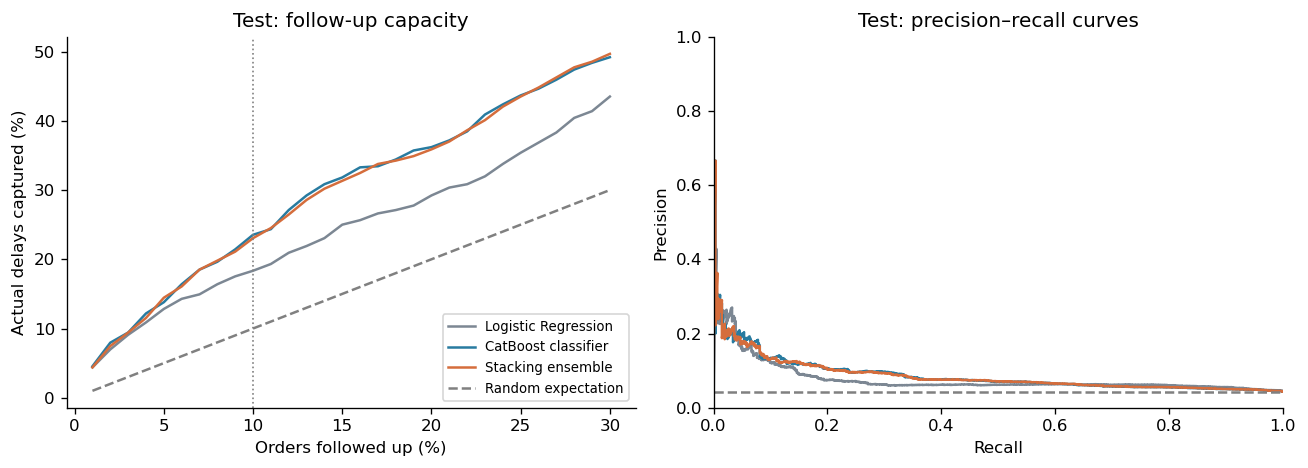

,Found,Recall,AP
"CatBoost, sequential history",145,23.5%,0.087
"CatBoost, history frozen at test start",192,31.2%,0.116
"Stacking, sequential history",142,23.1%,0.087
"Stacking, history frozen at test start",190,30.8%,0.114


Post-test diagnostic: CatBoost global top-10% shortlist by approval month


,Orders,Late,Selected,Found,Late rate,Share of alerts
order_approved_at,,,,,,
2018-06,2393,24,9,0,1.0%,0.6%
2018-07,5485,188,506,47,3.4%,35.5%
2018-08,6388,404,912,98,6.3%,63.9%


In [17]:
capacity_rows = []
for capacity in [0.05, 0.10, 0.15, 0.20]:
    for name, p in test_scores.items():
        capacity_rows.append(
            {
                "Capacity": f"{capacity:.0%}",
                "Model": name,
                **evaluate(test.late_delivery, p, capacity),
            }
        )
capacity_table = pd.DataFrame(capacity_rows)
show_results(
    capacity_table.set_index(["Capacity", "Model"]),
    ["Selected", "Found", "Recall", "Precision", "Lift"],
)

colors = ["#7c8793", "#287ba0", "#d56d3c"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
capacities = np.linspace(0.01, 0.30, 30)
for (name, p), color in zip(test_scores.items(), colors):
    gains = [evaluate(test.late_delivery, p, c)["Recall"] for c in capacities]
    axes[0].plot(capacities * 100, np.array(gains) * 100, label=name, color=color)
    precision, recall, _ = precision_recall_curve(test.late_delivery, p)
    axes[1].plot(recall, precision, label=name, color=color)
axes[0].plot(capacities * 100, capacities * 100, "--", color="gray", label="Random expectation")
axes[0].axvline(10, color="gray", linestyle=":", linewidth=1)
axes[0].set(
    xlabel="Orders followed up (%)",
    ylabel="Actual delays captured (%)",
    title="Test: follow-up capacity",
)
axes[1].axhline(test.late_delivery.mean(), color="gray", linestyle="--")
axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Test: precision–recall curves",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

# Fixed models; this is a sensitivity analysis, not another selection step.
frozen_test_history = historical_features(df, test, TEST)
test_adv_frozen = final_advanced.predict_proba(engineered(test, final_train, frozen_test_history))[
    :, 1
]
test_stack_frozen = final_meta.predict_proba(
    meta_inputs(np.c_[test_lr, test_adv_frozen], meta_form)
)[:, 1]
show_results(
    pd.DataFrame(
        {
            "CatBoost, sequential history": evaluate(test.late_delivery, test_adv),
            "CatBoost, history frozen at test start": evaluate(test.late_delivery, test_adv_frozen),
            "Stacking, sequential history": evaluate(test.late_delivery, test_stack),
            "Stacking, history frozen at test start": evaluate(
                test.late_delivery, test_stack_frozen
            ),
        }
    ).T,
    ["Found", "Recall", "AP"],
)

# Post-test description only: how the fixed global shortlist is allocated over time.
allocation = test[[T, "late_delivery"]].copy()
allocation["Selected"] = 0
allocation.loc[allocation.index[top_indices(test_adv)], "Selected"] = 1
allocation["Found"] = allocation.Selected * allocation.late_delivery
monthly_test = allocation.groupby(allocation[T].dt.to_period("M")).agg(
    Orders=("late_delivery", "size"),
    Late=("late_delivery", "sum"),
    Selected=("Selected", "sum"),
    Found=("Found", "sum"),
)
monthly_test["Late rate"] = monthly_test.Late / monthly_test.Orders
monthly_test["Share of alerts"] = monthly_test.Selected / monthly_test.Selected.sum()
print("Post-test diagnostic: CatBoost global top-10% shortlist by approval month")
display(monthly_test.style.format({"Late rate": "{:.1%}", "Share of alerts": "{:.1%}"}))

Use a paired **approval-week block bootstrap** to describe uncertainty in the 10% ranking. Resample weeks, rerank the sampled orders, and keep the three models' samples identical. These intervals describe variability of the fixed predictions; they do not include uncertainty from model development or guarantee future performance.

In [18]:
weeks = test.groupby(test[T].dt.to_period("W")).indices
blocks = list(weeks.values())
rng = np.random.default_rng(SEED)
boot = []
y_test = test.late_delivery.to_numpy()
for _ in range(500):
    indices = np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))])
    row = {}
    for name, p in test_scores.items():
        yy, pp = y_test[indices], p[indices]
        row[name] = yy[top_indices(pp)].sum() / yy.sum()
    row["CatBoost minus Logistic"] = row[MODEL_NAMES[1]] - row[MODEL_NAMES[0]]
    row["Stack minus Logistic"] = row[MODEL_NAMES[2]] - row[MODEL_NAMES[0]]
    row["Stack minus CatBoost"] = row[MODEL_NAMES[2]] - row[MODEL_NAMES[1]]
    boot.append(row)
bootstrap = pd.DataFrame(boot)
intervals = bootstrap.quantile([0.025, 0.975]).T.rename(
    columns={0.025: "95% lower", 0.975: "95% upper"}
)
display(intervals.style.format("{:.1%}"))

,95% lower,95% upper
Logistic Regression,15.8%,25.4%
CatBoost classifier,19.5%,28.8%
Stacking ensemble,19.6%,28.2%
CatBoost minus Logistic,-1.1%,9.7%
Stack minus Logistic,-0.7%,8.9%
Stack minus CatBoost,-1.4%,0.8%


## 9. Model Interpretation

CatBoost's native importance describes how fitted prediction values change across tree splits. It is an association measure, not a causal effect; correlated features may share importance. Interpret groups of related signals rather than treating every rank as precise.

Regional delivery history, ZIP geography, relative promise, seller identity, and freight per item lead the fitted model. These signals agree with the EDA's geography–promise relationship. At the selected settings, validation recall rises from **28.5%** with basic CatBoost inputs to **30.7%** with expanded static inputs and **36.2%** with sequential history.

The final meta-learner puts most weight on the CatBoost score. The two models do find some different delays, but the stack's development gain is only three orders, and it loses three relative to CatBoost on the test. High importance for regional history does not imply that updates remain useful in every future period.


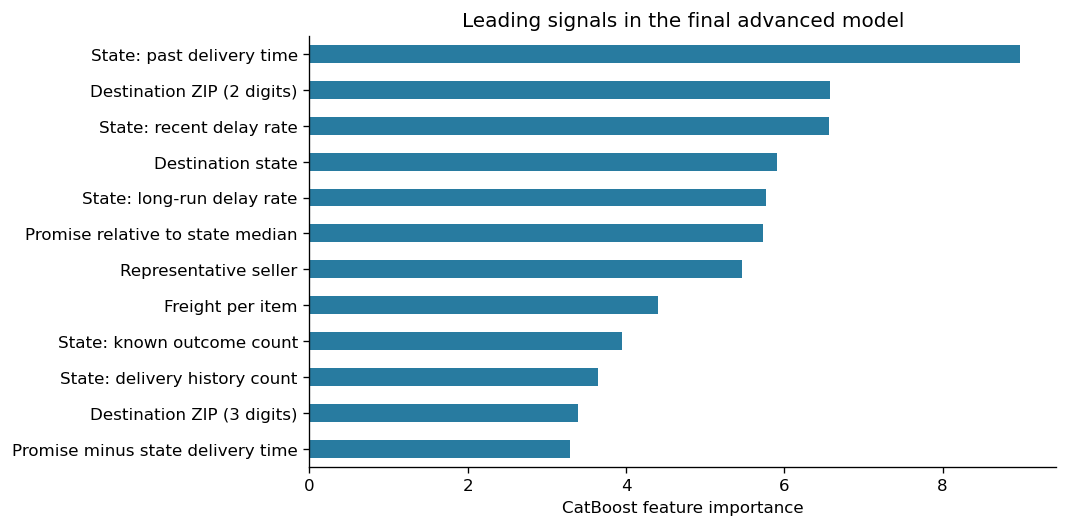

,Importance
customer_state_days_all,8.98
zip2,6.58
customer_state_late_delivery_90,6.57
customer_state,5.90
customer_state_late_delivery_all,5.77
relative_promised_delivery_days,5.73
seller_id,5.46
freight_per_item,4.41
customer_state_late_delivery_all_count,3.94
customer_state_days_all_count,3.64


,Standardized meta coefficient
Logistic score input,0.038
CatBoost score input,0.470


Leading signals: customer_state_days_all, zip2, customer_state_late_delivery_90, customer_state, customer_state_late_delivery_all
Feature ablation and overlap counts above show whether added information and stacking help; importance alone cannot establish an improvement.


In [19]:
importance = pd.Series(
    final_advanced.feature_importances_, index=final_advanced.feature_names_
).sort_values(ascending=False)
friendly_names = {
    "customer_state_days_all": "State: past delivery time",
    "zip2": "Destination ZIP (2 digits)",
    "customer_state_late_delivery_90": "State: recent delay rate",
    "customer_state": "Destination state",
    "customer_state_late_delivery_all": "State: long-run delay rate",
    "relative_promised_delivery_days": "Promise relative to state median",
    "seller_id": "Representative seller",
    "freight_per_item": "Freight per item",
    "customer_state_late_delivery_all_count": "State: known outcome count",
    "customer_state_days_all_count": "State: delivery history count",
    "zip3": "Destination ZIP (3 digits)",
    "customer_state_arrival_buffer": "Promise minus state delivery time",
}
fig, ax = plt.subplots(figsize=(9, 4.5))
importance.head(12).rename(index=friendly_names).sort_values().plot.barh(ax=ax, color="#287ba0")
ax.set(xlabel="CatBoost feature importance", title="Leading signals in the final advanced model")
fig.tight_layout()
plt.show()
display(importance.head(12).round(2).to_frame("Importance"))

if hasattr(final_meta, "named_steps"):
    coefficients = final_meta.named_steps["logisticregression"].coef_[0]
    display(
        pd.Series(
            coefficients,
            index=["Logistic score input", "CatBoost score input"],
            name="Standardized meta coefficient",
        )
        .round(3)
        .to_frame()
    )
print("Leading signals:", ", ".join(importance.head(5).index))
print(
    "Feature ablation and overlap counts above show whether added information and stacking help; "
    "importance alone cannot establish an improvement."
)

## 10. Conclusion and Business Implications

Read the test outcomes below at the fixed 10% follow-up workload. The model nominates orders for review; this dataset does not measure whether contacting customers prevents delays or improves satisfaction. Precision also quantifies the false-alert burden.

In [20]:
base, advanced, stack = (test_table.loc[name] for name in MODEL_NAMES)
lines = [
    f"- **{name}:** finds {int(row.Found):,} of {int(test.late_delivery.sum()):,} delayed orders; "
    f"recall **{row.Recall:.1%}**, precision **{row.Precision:.1%}**, lift **{row.Lift:.2f}×**."
    for name, row in test_table.iterrows()
]
lines += [
    f"- CatBoost finds **{int(advanced.Found - base.Found):+d}** more delayed orders than Logistic at the same workload.",
    f"- Stacking changes the number found by **{int(stack.Found - advanced.Found):+d}** versus CatBoost "
    f"and **{int(stack.Found - base.Found):+d}** versus Logistic.",
    f'- On the original validation orders, recall was {validation_table.loc[MODEL_NAMES[0], "Recall"]:.1%}, '
    f'{validation_table.loc[MODEL_NAMES[1], "Recall"]:.1%}, and '
    f'{validation_table.loc[MODEL_NAMES[2], "Recall"]:.1%}. '
    "The previous Logistic and arrival CatBoost scores were 32.8% and 32.6%. "
    "The previous 40.9% later-period score is not an overall benchmark.",
]
if (
    intervals.loc["Stack minus CatBoost", "95% lower"]
    <= 0
    <= intervals.loc["Stack minus CatBoost", "95% upper"]
):
    lines.append(
        "- The block-bootstrap interval for stacking minus CatBoost includes zero; its incremental value is uncertain."
    )
else:
    lines.append(
        "- The block-bootstrap interval for stacking minus CatBoost excludes zero on this test; this remains a single-period result."
    )
display(Markdown("\n".join(lines)))

- **Logistic Regression:** finds 113 of 616 delayed orders; recall **18.3%**, precision **7.9%**, lift **1.83×**.
- **CatBoost classifier:** finds 145 of 616 delayed orders; recall **23.5%**, precision **10.2%**, lift **2.35×**.
- **Stacking ensemble:** finds 142 of 616 delayed orders; recall **23.1%**, precision **10.0%**, lift **2.30×**.
- CatBoost finds **+32** more delayed orders than Logistic at the same workload.
- Stacking changes the number found by **-3** versus CatBoost and **+29** versus Logistic.
- On the original validation orders, recall was 33.9%, 36.2%, and 36.7%. The previous Logistic and arrival CatBoost scores were 32.8% and 32.6%. The previous 40.9% later-period score is not an overall benchmark.
- The block-bootstrap interval for stacking minus CatBoost includes zero; its incremental value is uncertain.

**The validation improvement did not transfer reliably to the test period.** CatBoost is the strongest of the three at the primary 10% capacity, but recall falls from 36.2% in validation to 23.5% on test. Stacking does not improve on CatBoost. The tested pipeline provides a useful ranking signal, with many false alerts and missed delays remaining. Week-block intervals for gains over Logistic include zero, so the point estimates do not establish reliable superiority.

The frozen-history sensitivity reaches 31.2% test recall for CatBoost, versus 23.5% with sequential updates. We retain the preselected sequential result as the primary result; choosing frozen history after seeing test outcomes would reuse the test for optimization. Test delay prevalence rises from 1.0% in the June portion to 3.4% in July and 6.3% in August. The same-test comparison shows that the history-update policy transfers poorly to this period; class prevalence cannot explain that difference because the evaluated orders are identical. Changing monthly rates document temporal shift, but these diagnostics do not isolate the cause of the deterioration.

Direct classification, outcome-available training, EDA-driven features, and OOF stacking improve the development pipeline. Short windows, weighting, duplicated positives, richer calendar terms, and deeper models did not consistently help. A next study should reassess history updates and calibration across several chronological periods, then reserve a **new** final holdout.

**Scope:** the cohort excludes cancellations and undelivered orders; original shipment filtering can affect generalization. Full-data EDA and repeated validation searches limit broad claims. Seller locations, distances, and product dimensions are unavailable locally. Customer-service benefits such as fewer complaints or prevented delays require an operational evaluation; this dataset measures order identification only.